# Chapter 5 실습. 해지 요인을 경영진에 어떻게 보고할까? — 풀이본
_모든 [직접 작성] 셀과 [판단] 칸을 채운 버전입니다. 숫자는 Telco 데이터(7,043명)로 실제 실행한 결과 기준이며, 라이브러리 버전에 따라 소수점 셋째 자리가 조금 다를 수 있습니다._
_각 [판단] 아래의 💡 칸은 이해를 돕기 위한 쉬운 설명입니다. 제출할 때는 지워도 됩니다._

In [1]:
# [제공] 이 실습에서 쓰는 라이브러리
import platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
import shap
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, average_precision_score

if platform.system() == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
elif platform.system() == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

---
# Part 1. 트리를 모으면 강해진다
## 1-1. 준비

In [2]:
# [제공] 데이터 준비
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df["target"] = (df["Churn"] == "Yes").astype(int)
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["target"])

num_cols = ["tenure", "MonthlyCharges", "SeniorCitizen"]
cat_cols = [c for c in df.columns if c not in num_cols + ["customerID", "Churn", "target", "TotalCharges"]]
features = num_cols + cat_cols
y_train, y_test = train_df["target"], test_df["target"]
print(len(train_df), len(test_df), "| 피처 수", len(features), "| 학습용 해지율", round(y_train.mean(), 3))

5634 1409 | 피처 수 18 | 학습용 해지율 0.265


In [3]:
# [제공] 실습 도구
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

def make_pipe(clf, scale=True):
    pre = ColumnTransformer([
        ("num", StandardScaler() if scale else "passthrough", num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ])
    return Pipeline([("pre", pre), ("clf", clf)])

def evaluate_model(name, model):
    s = cross_val_score(model, train_df[features], y_train, cv=cv, scoring="roc_auc")
    model.fit(train_df[features], y_train)
    p_te = model.predict_proba(test_df[features])[:, 1]
    p_tr = model.predict_proba(train_df[features])[:, 1]
    row = {"모델": name, "교차검증 AUC": f"{s.mean():.3f} ± {s.std():.3f}",
           "평가용 AUC": round(roc_auc_score(y_test, p_te), 3),
           "평가용 PR AUC": round(average_precision_score(y_test, p_te), 3),
           "학습용 AUC": round(roc_auc_score(y_train, p_tr), 3)}
    results.append(row)
    print(row)
    return model

def compare(name_a, model_a, name_b, model_b):
    s_a = cross_val_score(model_a, train_df[features], y_train, cv=cv, scoring="roc_auc")
    s_b = cross_val_score(model_b, train_df[features], y_train, cv=cv, scoring="roc_auc")
    diff = s_b - s_a
    print(f"{name_a}: {s_a.round(3)} | 평균 {s_a.mean():.3f} ± {s_a.std():.3f}")
    print(f"{name_b}: {s_b.round(3)} | 평균 {s_b.mean():.3f} ± {s_b.std():.3f}")
    print(f"fold별 차이 (B - A): {diff.round(3)} | 평균 차이 {diff.mean():+.3f}")
    print()

def show_log():
    return pd.DataFrame(results)

## 1-2. 지니 계수 손으로 계산하기
**[직접 작성]**

In [4]:
def gini(p):
    return 2 * p * (1 - p)

g_before = gini(y_train.mean())
print(f"나누기 전: 해지율 {y_train.mean():.3f}, 지니 {g_before:.3f}")

m = train_df["Contract"] == "Month-to-month"          # True = 월 단위 상자
p_left, p_right = y_train[m].mean(), y_train[~m].mean()
print(f"월 단위 상자: {m.sum()}명, 해지율 {p_left:.3f}, 지니 {gini(p_left):.3f}")
print(f"그 외 상자:   {(~m).sum()}명, 해지율 {p_right:.3f}, 지니 {gini(p_right):.3f}")

g_split = m.mean() * gini(p_left) + (~m).mean() * gini(p_right)   # 고객 수 비율로 가중 평균
print(f"G_split = {g_split:.3f}, ΔG = {g_before - g_split:.3f}")

나누기 전: 해지율 0.265, 지니 0.390
월 단위 상자: 3102명, 해지율 0.427, 지니 0.489
그 외 상자:   2532명, 해지율 0.067, 지니 0.125
G_split = 0.325, ΔG = 0.064


> **[판단]** 월 단위 상자의 지니 계수는 나누기 전보다 커졌습니다. 그런데도 전체로는 섞임이 줄어든 이유는 무엇인가요?
>
> **나의 답:** 월 단위 상자는 해지율이 0.265 → 0.427로 50%에 가까워져 지니가 0.390 → 0.489로 커졌지만, 나머지 상자(1년·2년 계약, 2,532명)는 해지율 0.067로 거의 '해지 안 함'만 남아 지니가 0.125로 크게 떨어졌습니다. 나눈 뒤의 지니는 두 상자를 고객 수로 가중 평균한 값(0.55×0.489 + 0.45×0.125 ≈ 0.325)이므로, 한쪽이 조금 나빠져도 다른 쪽이 훨씬 깨끗해지면 전체는 0.064만큼 줄어듭니다.

💡 **쉽게 말하면:** 한 상자를 '거의 다 안 떠나는 고객'으로 깨끗하게 만든 대신, 다른 상자에 해지 고객이 몰려 반반에 가까워졌습니다. 트리는 상자 하나가 아니라 **두 상자의 평균**으로 판단하기 때문에 전체적으로는 이득입니다.

## 1-3. 트리 하나의 한계
### 먼저 예상하기

> **[판단]** 예상: 깊이 제한 없이 끝까지 자란 트리의 학습용 AUC와 평가용 AUC는 각각 얼마쯤일까요? 깊이 3 트리(평가용 약 0.82)보다 나을까요?
>
> **나의 답:** 학습용 AUC는 학습 데이터를 거의 외우므로 1.0에 가깝고, 평가용 AUC는 0.7 안팎으로 깊이 3 트리(0.82)보다 나쁠 것 같다.

💡 **쉽게 말하면:** 이 칸은 '예상'이라 틀려도 괜찮습니다. 결과를 본 뒤 비교하는 게 목적입니다.

**[직접 작성]**

In [5]:
for d in [3, 6, None]:
    name = f"트리 깊이 {d}" if d else "트리 깊이 제한 없음"
    evaluate_model(name, make_pipe(DecisionTreeClassifier(max_depth=d, random_state=42), scale=False))

{'모델': '트리 깊이 3', '교차검증 AUC': '0.817 ± 0.006', '평가용 AUC': 0.818, '평가용 PR AUC': 0.556, '학습용 AUC': 0.824}


{'모델': '트리 깊이 6', '교차검증 AUC': '0.824 ± 0.011', '평가용 AUC': 0.835, '평가용 PR AUC': 0.617, '학습용 AUC': 0.865}


{'모델': '트리 깊이 제한 없음', '교차검증 AUC': '0.658 ± 0.013', '평가용 AUC': 0.669, '평가용 PR AUC': 0.39, '학습용 AUC': 1.0}


> **[판단]** 예상은 맞았나요? 깊이 제한 없는 트리의 학습용 AUC와 평가용 AUC의 차이를 "편향"과 "분산" 중 무엇으로 설명할 수 있나요? 깊이 3 트리는 어느 쪽의 문제가 더 클까요?
>
> **나의 답:** 예상대로였다. 깊이 제한 없는 트리는 학습용 1.000, 평가용 0.669로 차이가 0.33이나 된다. 학습 데이터의 우연한 패턴까지 외워서 데이터가 조금만 바뀌어도 예측이 크게 흔들리는 것이므로 **분산** 문제다. 깊이 3 트리는 학습용 0.824, 평가용 0.818로 거의 같고 둘 다 낮으므로, 외운 게 아니라 모델이 너무 단순해서 패턴을 다 못 잡는 **편향** 문제가 더 크다. 깊이 6(평가용 0.835)이 그 중간 정도다.

💡 **쉽게 말하면:** **분산** = 시험 문제를 통째로 외운 학생(연습 문제 만점, 실제 시험 망침). **편향** = 공부를 너무 대충 한 학생(연습도 시험도 비슷하게 어중간). 학습용과 평가용 점수의 **차이가 크면 분산**, 둘 다 낮으면 편향입니다.

## 1-4. 트리들을 서로 다르게: 배깅과 랜덤포레스트

In [6]:
# [제공] 전처리한 데이터 (트리용: 스케일링 없음)
pre_tree = ColumnTransformer([
    ("num", "passthrough", num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])
X_tr_t = pd.DataFrame(pre_tree.fit_transform(train_df[features]), columns=pre_tree.get_feature_names_out())
X_te_t = pd.DataFrame(pre_tree.transform(test_df[features]), columns=pre_tree.get_feature_names_out())
print(X_tr_t.shape, X_te_t.shape)

(5634, 44) (1409, 44)


**[직접 작성]** 부트스트랩 20번, 첫 질문 피처 세기

In [7]:
rng = np.random.RandomState(42)
roots_bag, roots_rf = [], []
for b in range(20):
    idx = rng.randint(0, len(X_tr_t), len(X_tr_t))          # 복원 추출
    Xb, yb = X_tr_t.iloc[idx], y_train.iloc[idx]
    t_bag = DecisionTreeClassifier(max_depth=3, random_state=b).fit(Xb, yb)
    t_rf  = DecisionTreeClassifier(max_depth=3, max_features="sqrt", random_state=b).fit(Xb, yb)
    roots_bag.append(X_tr_t.columns[t_bag.tree_.feature[0]])
    roots_rf.append(X_tr_t.columns[t_rf.tree_.feature[0]])

print("[배깅] 첫 질문에 쓰인 피처"); print(pd.Series(roots_bag).value_counts(), "\n")
print("[피처 후보 제한] 첫 질문에 쓰인 피처"); print(pd.Series(roots_rf).value_counts())

[배깅] 첫 질문에 쓰인 피처
cat__Contract_Month-to-month    20
Name: count, dtype: int64 

[피처 후보 제한] 첫 질문에 쓰인 피처
num__tenure                                  3
cat__Contract_Month-to-month                 3
cat__TechSupport_No internet service         2
cat__PaymentMethod_Electronic check          2
cat__TechSupport_No                          2
cat__Contract_One year                       1
cat__DeviceProtection_No internet service    1
cat__InternetService_Fiber optic             1
num__MonthlyCharges                          1
cat__Contract_Two year                       1
cat__PaperlessBilling_No                     1
cat__StreamingMovies_No internet service     1
cat__StreamingTV_No internet service         1
Name: count, dtype: int64


> **[판단]** 두 방법의 첫 질문은 어떻게 다른가요? 교안 1-3의 식 $\rho\sigma^2 + (1-\rho)\sigma^2/B$와 연결해, 피처 후보를 제한하면 왜 평균의 효과가 커지는지 설명해 보세요.
>
> **나의 답:** 배깅은 20번 모두 첫 질문이 '월 단위 계약'이었다. 표본을 바꿔도 가장 강한 피처가 매번 맨 위를 차지하니 트리들이 거의 똑같다(상관 ρ가 큼). 피처 후보를 제한하면 첫 질문이 13가지로 갈렸다(가입 기간, 월 단위 계약, 기술지원 없음, 전자수표 결제 등). 
> 식에서 B(트리 수)를 늘려 줄일 수 있는 건 뒤쪽 (1−ρ)σ²/B뿐이고, 앞쪽 ρσ²는 트리를 아무리 많이 모아도 남는다. 트리들이 서로 비슷하면(ρ가 크면) 평균을 내도 줄어드는 분산이 적다. 피처 후보를 제한하면 트리들이 서로 달라져 ρ가 작아지고, 그만큼 평균으로 지울 수 있는 분산이 커진다.

💡 **쉽게 말하면:** 똑같은 의견을 가진 사람 20명에게 물어보면 한 명에게 묻는 것과 별 차이가 없습니다. 서로 다른 관점을 가진 20명에게 물어야 '다수결'이 의미가 있죠. 랜덤포레스트는 일부러 각 트리가 다른 피처를 보게 만들어 '다양한 의견'을 만드는 방법입니다.

**[직접 작성]** 랜덤포레스트 두 개

In [8]:
evaluate_model("랜덤포레스트 기본값",
               make_pipe(RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1), scale=False))
evaluate_model("랜덤포레스트 잎 최소 20",
               make_pipe(RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=42, n_jobs=-1), scale=False))

{'모델': '랜덤포레스트 기본값', '교차검증 AUC': '0.813 ± 0.012', '평가용 AUC': 0.813, '평가용 PR AUC': 0.596, '학습용 AUC': 1.0}


{'모델': '랜덤포레스트 잎 최소 20', '교차검증 AUC': '0.846 ± 0.009', '평가용 AUC': 0.84, '평가용 PR AUC': 0.637, '학습용 AUC': 0.875}


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](18,)","['tenure','MonthlyCharges','SeniorCitizen',...,'Contract', 'PaperlessBilling','PaymentMethod']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,18
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthro

> **[판단]** 기본값 랜덤포레스트의 학습용 AUC와 평가용 AUC를 보세요. "앙상블이니까 과적합하지 않는다"는 말은 맞나요? 잎의 최소 고객 수를 늘리면 무엇이 달라지나요?
>
> **나의 답:** 맞지 않다. 기본값 랜덤포레스트는 학습용 AUC 1.000, 평가용 0.813으로 학습 데이터를 다 외웠고, 평가용은 깊이 3 트리 하나(0.818)보다도 낮다. 끝까지 자란 트리를 평균해도 개별 트리의 과적합이 완전히 사라지지 않는다. 잎에 최소 20명을 두면 트리가 몇 명짜리 특이 사례를 외우지 못해 학습용 0.875, 평가용 0.840으로 차이가 줄고 평가 성능은 오히려 올라갔다(교차검증 0.813 → 0.846).

💡 **쉽게 말하면:** '트리 수를 늘려도 과적합이 심해지지 않는다'와 '과적합하지 않는다'는 다른 말입니다. 트리 하나하나가 외우고 있으면 평균도 어느 정도 외운 상태가 됩니다. 그래서 잎 크기 같은 설정은 여전히 조절해야 합니다.

## 1-5. 부스팅: 트리를 더할수록
**[직접 작성]**

In [9]:
gb = GradientBoostingClassifier(n_estimators=500, learning_rate=0.1, max_depth=3, random_state=42).fit(X_tr_t, y_train)
rows = []
for i, (p_tr, p_te) in enumerate(zip(gb.staged_predict_proba(X_tr_t), gb.staged_predict_proba(X_te_t)), start=1):
    if i in [1, 10, 50, 100, 200, 500]:
        rows.append({"트리 수": i,
                     "학습용 AUC": round(roc_auc_score(y_train, p_tr[:, 1]), 3),
                     "평가용 AUC": round(roc_auc_score(y_test, p_te[:, 1]), 3)})
pd.DataFrame(rows)

,트리 수,학습용 AUC,평가용 AUC
0,1,0.824,0.818
1,10,0.849,0.839
2,50,0.868,0.844
3,100,0.879,0.843
4,200,0.895,0.838
5,500,0.930,0.828


> **[판단]** 트리 수를 늘릴 때 학습용과 평가용 AUC는 각각 어떻게 움직이나요? 랜덤포레스트의 트리 수와 무엇이 다른가요? 이 표를 보고 트리 수를 고르면 어떤 문제가 있을까요? (Chapter 4 3-1)
>
> **나의 답:** 학습용 AUC는 0.824 → 0.930으로 계속 오른다. 평가용 AUC는 50~100개에서 0.843~0.844로 가장 높았다가 200개 0.838, 500개 0.828로 다시 떨어진다. 부스팅은 앞 트리가 틀린 부분을 다음 트리가 계속 고치므로, 너무 많이 더하면 학습 데이터의 잡음까지 맞추며 과적합한다. 랜덤포레스트는 트리를 독립적으로 만들어 평균하므로 트리 수를 늘려도 성능이 안정될 뿐 나빠지지 않는다. 
> 그런데 이 표는 **평가용 데이터**를 보면서 만든 것이다. 여기서 '평가용이 가장 좋은 100개'를 고르면 평가용 데이터를 모델 선택에 써 버린 셈이라, 평가용 AUC가 실제보다 좋게 보이게 된다. 트리 수는 학습용 안에서 교차검증(또는 검증용 데이터)으로 골라야 한다.

💡 **쉽게 말하면:** 부스팅 = 오답 노트를 계속 쓰는 학생. 처음엔 실력이 늘지만 너무 오래 하면 '이 문제집의 특이한 문제'까지 외우게 됩니다. 그리고 '시험지를 보고 공부 시간을 정하는 것'은 반칙이라는 게 마지막 질문의 핵심입니다.

## 1-6. 더 강한 모델은 얼마나 강한가
**[직접 작성]**

In [10]:
evaluate_model("로지스틱 회귀", make_pipe(LogisticRegression(max_iter=3000)))
gbm_model = evaluate_model("경사 부스팅 기본값", make_pipe(GradientBoostingClassifier(random_state=42), scale=False))
show_log()

{'모델': '로지스틱 회귀', '교차검증 AUC': '0.845 ± 0.012', '평가용 AUC': 0.839, '평가용 PR AUC': 0.63, '학습용 AUC': 0.848}


{'모델': '경사 부스팅 기본값', '교차검증 AUC': '0.848 ± 0.011', '평가용 AUC': 0.843, '평가용 PR AUC': 0.654, '학습용 AUC': 0.879}


,모델,교차검증 AUC,평가용 AUC,평가용 PR AUC,학습용 AUC
0,트리 깊이 3,0.817 ± 0.006,0.818,0.556,0.824
1,트리 깊이 6,0.824 ± 0.011,0.835,0.617,0.865
2,트리 깊이 제한 없음,0.658 ± 0.013,0.669,0.390,1.000
3,랜덤포레스트 기본값,0.813 ± 0.012,0.813,0.596,1.000
4,랜덤포레스트 잎 최소 20,0.846 ± 0.009,0.840,0.637,0.875
5,로지스틱 회귀,0.845 ± 0.012,0.839,0.630,0.848
6,경사 부스팅 기본값,0.848 ± 0.011,0.843,0.654,0.879


In [11]:
compare("트리 깊이 3", make_pipe(DecisionTreeClassifier(max_depth=3, random_state=42), scale=False),
        "경사 부스팅", make_pipe(GradientBoostingClassifier(random_state=42), scale=False))
compare("로지스틱 회귀", make_pipe(LogisticRegression(max_iter=3000)),
        "경사 부스팅", make_pipe(GradientBoostingClassifier(random_state=42), scale=False))

트리 깊이 3: [0.809 0.814 0.813 0.819 0.827] | 평균 0.817 ± 0.006
경사 부스팅: [0.841 0.833 0.843 0.861 0.86 ] | 평균 0.848 ± 0.011
fold별 차이 (B - A): [0.031 0.019 0.03  0.041 0.033] | 평균 차이 +0.031



로지스틱 회귀: [0.847 0.825 0.841 0.861 0.851] | 평균 0.845 ± 0.012
경사 부스팅: [0.841 0.833 0.843 0.861 0.86 ] | 평균 0.848 ± 0.011
fold별 차이 (B - A): [-0.006  0.008  0.003 -0.001  0.01 ] | 평균 차이 +0.003



> **[판단]** 앙상블은 트리 하나보다 분명히 나은가요? 로지스틱 회귀보다는 나은가요? Chapter 4의 기준(fold별 차이와 편차)으로 판단하세요. 성능만 본다면 어느 모델을 고르겠습니까?
>
> **나의 답:** 트리 하나보다는 **분명히 낫다**. 깊이 3 트리 대비 경사 부스팅은 5개 fold 모두에서 +0.019 ~ +0.041 높았고 평균 +0.031로, 편차(±0.01 안팎)보다 훨씬 크다. 
> 로지스틱 회귀보다는 **낫다고 말하기 어렵다**. fold별 차이가 −0.006 ~ +0.010으로 부호가 왔다 갔다 하고(2개 fold는 로지스틱이 더 높음), 평균 차이 +0.003은 각 모델의 편차(±0.011~0.012)보다 작다. 성능만 보면 둘은 사실상 같으므로, 더 단순하고 설명하기 쉬운 로지스틱 회귀를 고르겠다.

💡 **쉽게 말하면:** 5번 시험에서 매번 이기면 '실력 차이', 이겼다 졌다 하면 '운의 차이'입니다. 부스팅 vs 트리 하나는 전자, 부스팅 vs 로지스틱은 후자입니다.

> **[판단]** 그런데도 이 실습은 Part 2에서 경사 부스팅 모델을 설명에 씁니다. 성능이 비슷한데도 부스팅을 쓸 이유가 있다면 무엇일까요? (교안 1-7, 2-5)
>
> **나의 답:** ① 트리 모델은 "가입 6개월까지는 위험이 크다가 1~2년 지나면 줄어든다", "월 요금은 90달러를 넘어야 위험해진다"처럼 **꺾이는 지점(비선형)과 피처 간 상호작용**을 스스로 잡는다. 로지스틱 회귀는 이런 걸 직접 구간을 나눠 넣어 주지 않으면 "한 방향 직선"으로만 표현한다. ② SHAP의 TreeExplainer로 트리 모델의 기여도를 **정확하고 빠르게** 계산할 수 있어 고객별 설명(waterfall)을 만들기 좋다. ③ PR AUC는 0.654로 로지스틱(0.630)보다 약간 높아, 상위 위험 고객을 고르는 용도에서는 조금 나을 수 있다(다만 평가용 한 번 결과라 확정은 못 함).

💡 **쉽게 말하면:** 성능은 비슷해도 '설명할 때 보여 줄 수 있는 모양'이 더 풍부한 모델을 쓰는 겁니다. 로지스틱은 '가입 기간 +1개월마다 위험 −x' 한 줄, 부스팅+SHAP은 '어느 구간에서 꺾이는지'까지 보여 줍니다.

---
# Part 2. 모델이 무엇을 보는가
## 2-1. 피처 중요도 두 가지
**[직접 작성]**

In [12]:
imp = pd.Series(gbm_model.named_steps["clf"].feature_importances_,
                index=gbm_model.named_steps["pre"].get_feature_names_out()).sort_values(ascending=False)
print("[불순도 중요도 상위 5]"); print(imp.head(5).round(3), "\n")

perm = permutation_importance(gbm_model, test_df[features], y_test, scoring="roc_auc", n_repeats=10, random_state=42)
pimp = pd.Series(perm.importances_mean, index=features).sort_values(ascending=False)
print("[순열 중요도 상위 5]"); print(pimp.head(5).round(3))

[불순도 중요도 상위 5]
cat__Contract_Month-to-month        0.386
num__tenure                         0.182
num__MonthlyCharges                 0.101
cat__InternetService_Fiber optic    0.090
cat__OnlineSecurity_No              0.069
dtype: float64 



[순열 중요도 상위 5]
Contract           0.076
tenure             0.072
InternetService    0.009
MonthlyCharges     0.007
OnlineSecurity     0.006
dtype: float64


> **[판단]** 두 중요도의 순위는 어떻게 다른가요? 두 중요도로는 답할 수 없는 질문을 두 가지 적어 보세요.
>
> **나의 답:** 1·2위는 둘 다 계약 유형과 가입 기간으로 같다. 차이는 그 아래다. 불순도 중요도는 월 요금(0.101) > 광케이블(0.090) > 온라인 보안 없음(0.069)이고, 순열 중요도는 인터넷 종류(0.009) > 월 요금(0.007) > 온라인 보안(0.006)으로 3~5위 순서가 바뀌고, 1·2위(0.07대)와 나머지(0.01 미만)의 격차가 훨씬 크다. 순열 중요도로 보면 사실상 계약과 가입 기간 두 개가 성능을 거의 다 책임진다. 
> 답할 수 없는 질문: ① 가입 기간이 길면 해지 확률이 오르나 내리나(**방향**)? ② 월 요금은 몇 달러부터 위험해지나(**꺾이는 지점**)? ③ 이 고객은 **왜** 위험하다고 나왔나(**고객 한 명** 설명)?

💡 **쉽게 말하면:** 중요도는 '얼마나 많이 썼나'라는 크기만 알려 주는 숫자입니다. 어느 방향으로, 어디서부터, 누구에게 그런지는 알려 주지 않습니다. 그래서 SHAP이 필요합니다.

## 2-2. SHAP 값 계산하고 가산성 확인하기
**[직접 작성]**

In [13]:
pre, gbm = gbm_model.named_steps["pre"], gbm_model.named_steps["clf"]
X_test_t = pd.DataFrame(pre.transform(test_df[features]), columns=pre.get_feature_names_out())
explainer = shap.TreeExplainer(gbm)
shap_values = explainer.shap_values(X_test_t)
base_value = float(np.ravel(explainer.expected_value)[0])
print("shap_values 모양:", shap_values.shape, "| 기준값(로그 오즈):", round(base_value, 3))

recon = base_value + shap_values[0].sum()
out = gbm.decision_function(X_test_t.iloc[[0]])[0]
print(f"첫 고객: 기준값 + 기여도 합 = {recon:.4f} | 모델 출력 = {out:.4f} | 같은가? {np.isclose(recon, out)}")
print("기준값을 확률로:", round(1 / (1 + np.exp(-base_value)), 3))

shap_values 모양: (1409, 44) | 기준값(로그 오즈): -1.594
첫 고객: 기준값 + 기여도 합 = -3.9382 | 모델 출력 = -3.9382 | 같은가? True
기준값을 확률로: 0.169


> **[판단]** 기준값을 확률로 바꾸면 얼마인가요? 학습용 해지율(약 0.265)과 같나요? 다르다면 왜 다를까요? (교안 3-2)
>
> **나의 답:** 기준값은 로그 오즈 −1.594, 확률로는 약 0.169로 학습용 해지율 0.265보다 낮다. 기준값은 '확률의 평균'이 아니라 '**로그 오즈의 평균**'이기 때문이다. 확률↔로그 오즈 변환(시그모이드)은 곡선이라, 평균을 먼저 내고 바꾸는 것과 바꾼 뒤 평균을 내는 것이 다르다. 이 데이터는 해지 확률이 아주 낮은 고객(장기 계약 등)이 많아 이들의 로그 오즈가 크게 음수(−4 근처)로 내려가고, 그것이 평균을 끌어내린다. 실제로 모델의 평균 예측 확률은 0.266으로 해지율과 거의 같다.

💡 **쉽게 말하면:** '평균 점수를 확률로 바꾼 것'과 '확률의 평균'은 다릅니다. 0.01 같은 아주 작은 확률은 로그 오즈로 바꾸면 −4.6처럼 큰 음수가 되어 평균을 크게 끌어내리기 때문입니다.

## 2-3. 전체 그림: bar와 beeswarm
**[직접 작성]**

cat__Contract_Month-to-month           0.639
num__tenure                            0.506
cat__OnlineSecurity_No                 0.242
num__MonthlyCharges                    0.226
cat__TechSupport_No                    0.207
cat__InternetService_Fiber optic       0.199
cat__Contract_Two year                 0.169
cat__PaymentMethod_Electronic check    0.168
dtype: float64


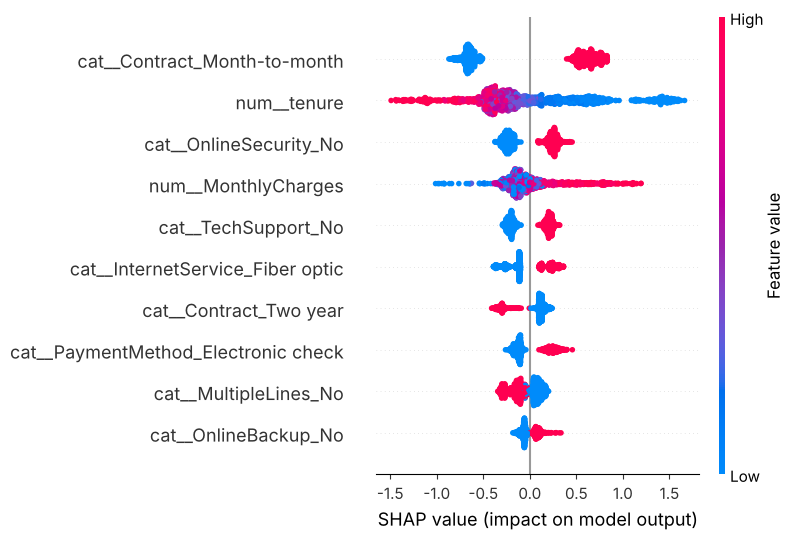

In [14]:
mean_abs = pd.Series(np.abs(shap_values).mean(axis=0), index=X_test_t.columns).sort_values(ascending=False)
print(mean_abs.head(8).round(3))
shap.summary_plot(shap_values, X_test_t, max_display=10)

> **[판단]** beeswarm 그래프에서 월 단위 계약과 가입 기간의 점은 각각 어느 쪽에 모여 있나요? "이 값이 크면 모델은 해지 확률을 올리는가, 내리는가"를 두 피처에 대해 적으세요.
>
> **나의 답:** **월 단위 계약**: 값이 0/1뿐이라 점이 두 덩어리로 갈린다. 빨간 점(월 단위 = 1)은 오른쪽(+0.6 안팎), 파란 점(월 단위 아님 = 0)은 왼쪽(−0.65 안팎)에 모여 있다. → 값이 크면(월 단위면) 모델은 해지 확률을 **올린다**. 
> **가입 기간**: 빨간 점(오래된 고객)은 왼쪽, 파란 점(신규 고객)은 오른쪽에 길게 퍼져 있다. 오른쪽 꼬리가 +1.5까지 길다. → 값이 크면(오래 쓴 고객이면) 모델은 해지 확률을 **내린다**. 반대로 신규 고객일수록 크게 올린다.

💡 **쉽게 말하면:** beeswarm 읽는 법: **가로 위치 = 해지 쪽으로 밀었나(오른쪽) 당겼나(왼쪽)**, **색 = 그 피처 값이 컸나(빨강) 작았나(파랑)**. '빨강이 오른쪽'이면 값이 클수록 위험, '빨강이 왼쪽'이면 값이 클수록 안전입니다.

## 2-4. 어디서 꺾이는가: dependence
**[직접 작성]**

In [15]:
cols = list(X_test_t.columns)

tenure_shap = pd.Series(shap_values[:, cols.index("num__tenure")])
tenure_bin = pd.cut(X_test_t["num__tenure"], [0, 6, 12, 24, 48, 72], include_lowest=True)
print("[가입 기간 구간별 평균 기여도]")
print(pd.DataFrame({"평균 기여도": tenure_shap.groupby(tenure_bin.values, observed=True).mean().round(3),
                    "고객 수": tenure_shap.groupby(tenure_bin.values, observed=True).size()}), "\n")

mc_shap = pd.Series(shap_values[:, cols.index("num__MonthlyCharges")])
mc_bin = pd.cut(X_test_t["num__MonthlyCharges"], [0, 40, 70, 90, 120], include_lowest=True)
print("[월 요금 구간별 평균 기여도]")
print(pd.DataFrame({"평균 기여도": mc_shap.groupby(mc_bin.values, observed=True).mean().round(3),
                    "고객 수": mc_shap.groupby(mc_bin.values, observed=True).size()}))

[가입 기간 구간별 평균 기여도]
               평균 기여도  고객 수
(-0.001, 6.0]   0.951   311
(6.0, 12.0]     0.325   138
(12.0, 24.0]   -0.027   206
(24.0, 48.0]   -0.283   304
(48.0, 72.0]   -0.579   450 

[월 요금 구간별 평균 기여도]
                평균 기여도  고객 수
(-0.001, 40.0]  -0.164   372
(40.0, 70.0]    -0.143   339
(70.0, 90.0]    -0.049   365
(90.0, 120.0]    0.459   333


> **[판단]** 가입 기간의 기여도는 어느 구간에서 가장 크고, 어디쯤에서 0을 지나나요? 월 요금은 "높을수록 해지"라고 말할 수 있나요? 이 결과를 CS팀에 어떤 행동 지침으로 전하겠습니까?
>
> **나의 답:** 가입 기간 기여도는 **0~6개월에서 +0.95로 가장 크고**, 6~12개월 +0.33, 12~24개월 −0.03으로 **1~2년 사이에서 0을 지난다**. 그 뒤로는 계속 음수(4년 이상 −0.58)다. 
> 월 요금은 40달러 이하 −0.16, 40~70 −0.14, 70~90 −0.05로 90달러까지는 거의 평평하거나 음수이고, **90달러를 넘는 구간에서만 +0.46으로 뛴다**. 그래서 "높을수록 해지"가 아니라 "**90달러 이상 고액 요금 구간에서** 위험 신호"라고 말해야 한다. 
> CS팀 지침: "가입 1년 미만, 특히 6개월 이내 고객과 월 90달러 이상 고객을 우선 관리 대상으로 보고 먼저 연락한다." (이건 '누구에게 먼저 연락할지'의 기준이지, 요금을 내리면 해지가 줄어든다는 뜻은 아니다.)

💡 **쉽게 말하면:** 평균 기여도가 **0을 지나는 지점**이 '위험 신호 → 안전 신호'로 바뀌는 경계입니다. 가입 기간은 약 1년, 월 요금은 90달러가 그 경계 역할을 합니다.

## 2-5. 고객 한 명: waterfall
**[직접 작성]**

해지 확률: 0.917
customerID            5178-LMXOP
tenure                         1
Contract          Month-to-month
MonthlyCharges              95.1
Name: 3380, dtype: object


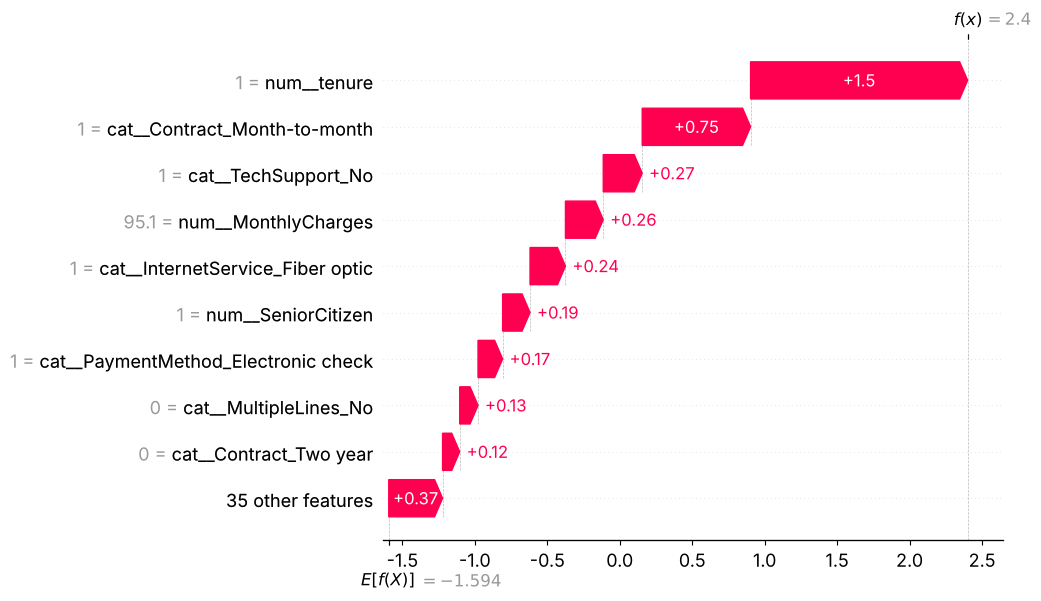

In [16]:
prob = gbm_model.predict_proba(test_df[features])[:, 1]
i = int(np.argmax(prob))
print("해지 확률:", round(prob[i], 3))
print(test_df.iloc[i][["customerID", "tenure", "Contract", "MonthlyCharges"]])
shap.plots.waterfall(shap.Explanation(values=shap_values[i], base_values=base_value,
                                      data=X_test_t.iloc[i], feature_names=cols))

> **[판단]** 이 고객에게 전화할 CS팀 상담원에게, 이 그래프를 한 문장으로 바꿔 전해 보세요. "이것을 바꾸면 해지하지 않는다"는 뜻이 들어가지 않도록 주의하세요.
>
> **나의 답:** "이 고객(5178-LMXOP)은 가입한 지 1개월 된 월 단위 계약 고객이고, 월 95달러 광케이블 요금제에 기술지원은 쓰지 않고 있어서, 모델이 해지 가능성이 매우 높은 고객(약 92%)으로 분류했습니다. 가입 초기에 겪는 불편이 있는지 먼저 여쭤봐 주세요."

💡 **쉽게 말하면:** '가입 기간이 짧아서 위험하다'는 '오래 쓰게 만들면 안 떠난다'가 아닙니다. 그래서 '~라서 위험 고객으로 **분류됐다**'처럼 **모델이 본 것**을 전달하고, 해결책을 약속하는 표현은 피합니다.

---
# Part 3. SHAP을 읽을 때의 함정
## 3-1. 상관 피처가 기여도를 나눠 가진다
### 먼저 예상하기

> **[판단]** 예상: 월 요금을 모델에서 빼고 다시 학습하면, 광케이블 인터넷의 기여도 절댓값 평균은 지금(2-3)보다 커질까요, 작아질까요, 그대로일까요?
>
> **나의 답:** 커질 것이다. 월 요금이 가져가던 '요금이 비싸다'는 정보를 광케이블이 대신 떠안을 것 같다.

💡 **쉽게 말하면:** 예상 칸이므로 자신의 처음 생각을 적으면 됩니다.

**[직접 작성]**

In [17]:
# 1) 상관계수
fiber = (test_df["InternetService"] == "Fiber optic").astype(int)
print("월 요금 vs 광케이블 여부 상관계수:", round(np.corrcoef(test_df["MonthlyCharges"], fiber)[0, 1], 3))

# 2) 현재 모델의 기여도
j_mc, j_fo = cols.index("num__MonthlyCharges"), cols.index("cat__InternetService_Fiber optic")
print("월 요금 |기여도| 평균:   ", round(np.abs(shap_values[:, j_mc]).mean(), 3))
print("광케이블 |기여도| 평균:  ", round(np.abs(shap_values[:, j_fo]).mean(), 3))
print("두 기여도를 더한 뒤 |평균|:", round(np.abs(shap_values[:, j_mc] + shap_values[:, j_fo]).mean(), 3))

# 3) 월 요금을 빼고 다시 학습
num_cols2 = ["tenure", "SeniorCitizen"]
features2 = num_cols2 + cat_cols
pre2 = ColumnTransformer([
    ("num", "passthrough", num_cols2),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])
gbm2 = Pipeline([("pre", pre2), ("clf", GradientBoostingClassifier(random_state=42))]).fit(train_df[features2], y_train)
X_test_t2 = pd.DataFrame(gbm2.named_steps["pre"].transform(test_df[features2]),
                         columns=gbm2.named_steps["pre"].get_feature_names_out())
sv2 = shap.TreeExplainer(gbm2.named_steps["clf"]).shap_values(X_test_t2)
j_fo2 = list(X_test_t2.columns).index("cat__InternetService_Fiber optic")
print("\n[월 요금 뺀 모델] 광케이블 |기여도| 평균:", round(np.abs(sv2[:, j_fo2]).mean(), 3))
print("[월 요금 뺀 모델] 평가용 AUC:", round(roc_auc_score(y_test, gbm2.predict_proba(test_df[features2])[:, 1]), 3))

월 요금 vs 광케이블 여부 상관계수: 0.785
월 요금 |기여도| 평균:    0.226
광케이블 |기여도| 평균:   0.199
두 기여도를 더한 뒤 |평균|: 0.385



[월 요금 뺀 모델] 광케이블 |기여도| 평균: 0.391
[월 요금 뺀 모델] 평가용 AUC: 0.847


> **[판단]** 예상은 맞았나요? 월 요금을 뺐을 때 광케이블의 기여도와 AUC가 어떻게 변했는지로, "해지 요인은 월 요금인가, 광케이블인가"라는 질문에 SHAP이 답할 수 있는지 판단하세요. 보고서에는 두 피처를 어떻게 적겠습니까?
>
> **나의 답:** 예상대로 커졌다. 두 피처의 상관계수는 0.785로 높다. 현재 모델에서는 월 요금 0.226, 광케이블 0.199로 기여도를 나눠 갖고 있었는데(둘을 더하면 0.385), 월 요금을 빼자 광케이블 기여도가 0.391로 거의 두 배가 되어 '둘의 합'만큼을 혼자 가져갔다. 그런데 평가용 AUC는 0.843 → 0.847로 **떨어지지 않았다**. 즉 모델 입장에서 월 요금이 하는 일을 광케이블이 거의 다 대신할 수 있다. 
> 그래서 SHAP으로는 "월 요금이냐 광케이블이냐"에 **답할 수 없다**. 어느 쪽에 기여도가 붙을지는 어떤 피처를 넣었느냐에 따라 달라질 뿐이다. 보고서에는 두 피처를 따로 순위 매기지 않고 "**광케이블 인터넷·고액 요금(월 90달러 이상)** 고객군" 하나로 묶어 적고, 둘이 서로 겹치는 정보라 어느 쪽이 영향인지는 이 분석으로 구분할 수 없다고 밝힌다.

💡 **쉽게 말하면:** 두 사람이 같이 한 일을 SHAP은 '반씩 나눠서' 점수를 줍니다. 한 명이 빠지면 남은 사람이 전부 가져갑니다. 그러니 '누가 진짜 일했나'는 SHAP 점수로 알 수 없습니다.

## 3-2. 단위는 로그 오즈

In [18]:
# [제공] 같은 기여도 +1.0, 다른 확률 변화
sigmoid = lambda z: 1 / (1 + np.exp(-z))
rows = []
for z in [-3, -2, -1, 0, 1]:
    rows.append({"출발 로그 오즈": z, "출발 확률": round(sigmoid(z), 3),
                 "+1.0 뒤의 확률": round(sigmoid(z + 1), 3), "확률 변화 (%p)": round((sigmoid(z + 1) - sigmoid(z)) * 100, 1)})
pd.DataFrame(rows)

,출발 로그 오즈,출발 확률,+1.0 뒤의 확률,확률 변화 (%p)
0,-3,0.047,0.119,7.2
1,-2,0.119,0.269,15.0
2,-1,0.269,0.500,23.1
3,0,0.500,0.731,23.1
4,1,0.731,0.881,15.0


> **[판단]** 어떤 보고서에 "월 단위 계약은 해지 확률을 평균 25%p 올린다"고 적혀 있습니다. 위 표를 근거로 이 문장의 문제를 설명하고, 같은 내용을 정직하게 바꿔 써 보세요.
>
> **나의 답:** 문제 1 (**단위**): SHAP 기여도는 확률(%p)이 아니라 로그 오즈 단위다. 위 표처럼 같은 +1.0이라도 출발 확률이 5%인 고객에게는 +7%p, 27~50%인 고객에게는 +23%p로 확률 변화가 다르다. 그래서 '평균 몇 %p'라는 하나의 숫자로 바꿀 수 없다. 
> 문제 2 (**인과**): '올린다'는 월 단위 계약이 해지를 일으킨다는 뜻으로 읽힌다. SHAP은 모델이 그 값을 보고 예측을 얼마나 움직였는지일 뿐이다. 
> 바꿔 쓴 문장: "모델은 월 단위 계약 고객의 해지 위험 점수를 일관되게 높게 매깁니다(로그 오즈 기준 평균 약 +0.6). 확률로 얼마나 높아지는지는 고객의 다른 조건에 따라 달라지며, 이 결과는 월 단위 계약이 해지의 원인이라는 뜻은 아닙니다."

💡 **쉽게 말하면:** 로그 오즈는 '확률의 자'가 휘어 있는 것과 같습니다. 가운데(50% 근처)에서는 한 칸이 크게, 양 끝(아주 낮거나 높은 확률)에서는 작게 움직입니다. 그래서 '+1칸 = 몇 %p'로 고정해서 말할 수 없습니다.

## 3-3. 보고서 문장 판별하기

> **[판단]** 1~5번 각각: 쓸 수 있다 / 쓸 수 없다(걸린 함정)
>
> **나의 답:** 1. **쓸 수 있다.** "모델이 신호로 사용한다"는 모델에 대한 서술이고, 실제로 SHAP 상위 1~3위가 월 단위 계약, 가입 기간, 온라인 보안 미가입이다. 
> 2. **쓸 수 없다 — 인과.** SHAP은 '모델이 무엇을 봤는지'만 보여 준다. 2년 계약 고객은 원래 충성도가 높은 고객일 수 있고, 계약을 바꾼다고 그 성향이 생기지는 않는다. 
> 3. **쓸 수 없다 — 상관 피처.** 3-1에서 봤듯 둘은 상관 0.785로 기여도를 나눠 가지며, 하나를 빼면 다른 쪽이 그대로 가져가 성능도 유지된다. 어느 쪽이 '진짜'인지 SHAP으로 가를 수 없다. ('요인'이라는 말도 원인처럼 읽혀 인과 함정까지 걸쳐 있다.) 
> 4. **쓸 수 있다(표현 주의).** 가입 기간 기여도가 0~6개월에서 +0.95로 가장 크고, 실제 데이터의 해지율도 이 구간이 약 53%로 가장 높아 '위험이 높다'는 관찰로서는 맞다. 다만 "가입 기간이 짧아서 해지한다"는 인과로 읽히지 않게 쓴다. 
> 5. **쓸 수 있다.** SHAP 결과를 근거로 삼되 효과는 무작위 시범 적용(실험)으로 확인하자는 제안이므로, 이 Chapter의 판단 포인트를 정확히 지킨 문장이다.

💡 **쉽게 말하면:** 판별 기준은 하나입니다: 문장이 '**모델이 무엇을 봤다/누가 위험해 보인다**'에서 멈추면 OK, '**바꾸면 줄어든다/이게 원인이다**'까지 가면 NO. 그 경계를 넘으려면 실험이 필요합니다.

---
# Part 4. 경영진과 CS팀에 보고하기
## 4-1. CS팀용 고객별 위험 신호
**[직접 작성]**

In [19]:
top10 = np.argsort(-prob)[:10]
rows = []
for k in top10:
    s = pd.Series(shap_values[k], index=cols).sort_values(ascending=False).head(3)
    row = {"고객 ID": test_df.iloc[k]["customerID"], "해지 확률": round(prob[k], 3)}
    for n, (f, v) in enumerate(s.items(), start=1):
        row[f"위험 신호 {n}"] = f"{f} ({v:+.2f})"
    rows.append(row)
pd.DataFrame(rows)

,고객 ID,해지 확률,위험 신호 1,위험 신호 2,위험 신호 3
0,5178-LMXOP,0.917,num__tenure (+1.50),cat__Contract_Month-to-month (+0.75),cat__TechSupport_No (+0.27)
1,1069-XAIEM,0.910,num__tenure (+1.49),cat__Contract_Month-to-month (+0.78),cat__TechSupport_No (+0.26)
2,0295-PPHDO,0.910,num__tenure (+1.37),cat__Contract_Month-to-month (+0.75),num__MonthlyCharges (+0.28)
3,6861-XWTWQ,0.899,num__MonthlyCharges (+0.73),cat__Contract_Month-to-month (+0.72),num__tenure (+0.63)
4,0970-ETWGE,0.896,num__tenure (+1.52),cat__Contract_Month-to-month (+0.77),num__MonthlyCharges (+0.32)
5,6230-BSUXY,0.889,num__tenure (+1.59),cat__Contract_Month-to-month (+0.77),cat__TechSupport_No (+0.25)
6,6023-YEBUP,0.887,num__tenure (+0.79),cat__Contract_Month-to-month (+0.71),num__MonthlyCharges (+0.59)
7,1628-BIZYP,0.872,num__tenure (+1.48),cat__Contract_Month-to-month (+0.77),cat__InternetService_Fiber optic (+0.26)
8,0655-RBDUG,0.871,num__MonthlyCharges (+0.79),num__tenure (+0.74),cat__Contract_Month-to-month (+0.72)
9,9248-OJYKK,0.869,num__tenure (+1.46),cat__Contract_Month-to-month (+0.83),cat__TechSupport_No (+0.26)


> **[판단]** 이 표를 상담원이 그대로 쓰기에는 무엇이 불편한가요? 상담원용으로 바꾼다면 위험 신호 열을 어떤 말로 바꾸겠습니까? 한 고객을 골라 예를 들어 보세요.
>
> **나의 답:** 불편한 점: ① `num__tenure`, `cat__Contract_Month-to-month` 같은 코드식 열 이름이라 무슨 뜻인지 모른다. ② 괄호 속 +1.50 같은 숫자는 로그 오즈라 상담원이 해석할 수 없고, 오히려 '%'로 오해할 수 있다. ③ "가입 기간"만 있고 실제 값(몇 개월인지)이 없어 높은 건지 낮은 건지 모른다. ④ 상위 10명이 거의 똑같은 신호(가입 기간, 월 단위)라 고객별 차이를 알기 어렵다. 
> 바꾸는 방식: 피처 이름 대신 **실제 값이 들어간 쉬운 문장**으로, 숫자 대신 강도를 '매우 강함/강함/보통' 정도로 표시한다. 
> 예: 고객 6861-XWTWQ (해지 위험 매우 높음, 상위 1%) 
> - 위험 신호 1: 월 요금이 높음 (월 90달러 이상 요금제) — 강함 
> - 위험 신호 2: 약정 없는 월 단위 계약 — 강함 
> - 위험 신호 3: 가입 1년 미만 신규 고객 — 보통 
> → 상담 포인트: 요금 부담 체감과 서비스 만족도를 먼저 여쭤보기 (※ 위험 신호는 '이런 특징 때문에 위험 고객으로 분류됨'이라는 뜻이며, 할인·계약 변경의 효과를 보장하지 않음)

💡 **쉽게 말하면:** 데이터 분석가가 읽는 표와 현장 직원이 쓰는 표는 다르게 만들어야 합니다. '+0.73'보다 '월 95달러 요금제 사용 중'이 상담원에게 훨씬 쓸모 있습니다.

## 4-2. 경영진 보고 메모

> **[판단]** 경영진 보고 메모:
>
> **나의 답:** 팀장님, CS팀 해지 예측 모델을 분석한 결과를 보고드립니다. 
> 
> **1. 모델이 해지 위험 신호로 쓰는 요인 세 가지** 
> ① **월 단위(약정 없는) 계약** — 모델이 가장 크게 의존하는 신호입니다(전체 18개 항목 중 1위). 월 단위 고객은 위험 쪽으로, 1·2년 약정 고객은 안전 쪽으로 일관되게 분류됩니다. 
> ② **짧은 가입 기간** — 2위. 가입 6개월 이내에서 위험 신호가 가장 강하고(실제 해지율도 약 53%), 가입 1~2년 무렵을 지나면 오히려 안전 신호로 바뀝니다. 
> ③ **부가 서비스 미가입(온라인 보안·기술지원)과 고액 요금** — 3~5위권. 특히 요금은 '비쌀수록 위험'이 아니라 **월 90달러를 넘는 구간에서만** 위험 신호가 뚜렷해집니다. 
> 
> **2. "바꾸면 해지가 줄어든다"고 말할 수 있는 요인: 0개** 
> 위 요인은 '해지할 고객이 가진 특징'이지 '해지의 원인'으로 확인된 것이 아닙니다. 예를 들어 2년 약정 고객이 덜 떠나는 것은, 원래 오래 쓸 생각이 있는 고객이 약정을 고르기 때문일 수 있습니다. 이 경우 월 단위 고객에게 약정을 권해도 해지는 줄지 않을 수 있습니다. 과거 데이터만으로는 둘을 구분할 수 없습니다. 
> 
> **3. 제안: 소규모 무작위 시범 사업으로 확인** 
> 정책을 전사 적용하기 전에, 위험 고객(월 단위·가입 1년 미만) 중 일부를 무작위로 골라 ① 약정 전환 혜택 또는 ② 온라인 보안·기술지원 무료 제공을 시범 적용하고, 적용하지 않은 비교 그룹과 3~6개월 해지율을 비교하겠습니다. 여기서 실제로 해지가 줄어든 정책만 확대하는 것을 제안드립니다. 
> 
> **4. 주의할 점** 
> - **요금과 인터넷 종류는 구분이 안 됩니다.** 광케이블 고객 대부분이 고액 요금제여서, 해지 위험이 '요금 때문'인지 '광케이블 서비스 때문'인지 이 분석으로는 가를 수 없습니다. 한 항목으로 봐 주십시오. 
> - **모델 성능의 한계**: 이번 모델은 기존의 단순한 모델(로지스틱 회귀)과 정확도가 사실상 같습니다(차이가 측정 오차 범위 안). 더 정교한 모델이라 더 정확하다고 보시면 안 됩니다. 
> - 위의 순위는 '모델이 얼마나 많이 참고했는가'이지 '해지에 미치는 영향의 크기(몇 %)'가 아닙니다.

💡 **쉽게 말하면:** 메모 핵심 구조: **모델이 본 것(사실) → 원인이라고 단정할 수 없음(한계) → 그래서 실험으로 확인(제안)**. 머신러닝 용어(SHAP, AUC, 로그 오즈)는 하나도 쓰지 않았습니다.

---
# 마무리
> **SHAP이 큰 요인은 모델이 많이 쓴 요인이지 해지의 원인이 아니다. "요인을 바꾸면 결과가 바뀌는가"는 실험으로 확인한다.**

> **[판단]** 나의 체크리스트 8번(더 강한 모델을 고를 때):
>
> **나의 답:** "앙상블이 단순 모델보다 낫다"고 쓰기 전에, 같은 5겹에서 fold별 차이의 부호가 일관되고 평균 차이가 편차보다 큰지 확인한다. 부스팅의 트리 수처럼 평가용 데이터를 보고 설정을 고르지 않았는지도 확인한다. (오늘: 부스팅 vs 로지스틱 차이 +0.003, fold별로 이기고 지는 게 섞임)

> **[판단]** 나의 체크리스트 9번(모델 설명을 보고할 때):
>
> **나의 답:** ① '모델이 신호로 쓴다'를 '원인이다/바꾸면 줄어든다'로 바꿔 쓰지 않았는지, ② 로그 오즈 기여도를 %p로 옮겨 적지 않았는지, ③ 서로 상관이 높은 피처(월 요금·광케이블)를 따로 순위 매기지 않았는지 확인한다. (오늘: 월 요금을 빼자 광케이블 기여도가 0.20 → 0.39로 두 배가 됨)